In [81]:
from os import chdir
from os.path import abspath
thepath = abspath("../base")
chdir(thepath)

In [82]:
# yaml processing file loading. 
import yaml
import numpy as np
import matplotlib.pyplot as plt

from os.path import exists
from stl import mesh
from MST_centreline import return_MST_centrelines
from utils import return_edge_midpoints, find_neighbours_with_knn, adjust_plane

# to show the various clearance maps. 
from matplotlib.colors import Normalize 
from matplotlib.cm import ScalarMappable
from matplotlib.gridspec import GridSpec

A mapping to the conduits and their number.

In [83]:
with open(f"../notebooks/conduit_map.yaml", "r") as f: 
    conduit_map = yaml.safe_load(f)
    f.close()

A mapping of plotting keyword arguments.

In [84]:
with open(f"../notebooks/plot_kwargs.yaml", "r") as f: 
    p = yaml.safe_load(f)
    f.close()

In [85]:
skeleton_kwargs = p["skeleton_kwargs"]
node_kwargs = p["node_kwargs"]
ct_kwargs = p["ct_kwargs"]
ct1_kwargs = p["ct1_kwargs"]
ct2_kwargs = p["ct2_kwargs"]
mesh_kwargs = p["mesh_kwargs"]
start_kwargs = p["start_kwargs"]
end_kwargs = p["end_kwargs"]

In [86]:
# set up the conduit name and ID. 
ID = 10
CONDUIT_NAME = conduit_map[ID]

In [87]:
## import the mesh data. 
mesh_fp =  f"../data/{ID}_{CONDUIT_NAME}/{CONDUIT_NAME}.stl"
data = mesh.Mesh.from_file(mesh_fp)


In [88]:
adj_triangles_fp = mesh_fp[:-4] + "_adjacent_triangles.txt"
if not exists(adj_triangles_fp):
    triangle_adjacency_matrix = find_neighbours_with_knn(data)
    np.savetxt(adj_triangles_fp, triangle_adjacency_matrix)
else: 
    triangle_adjacency_matrix = np.loadtxt(adj_triangles_fp)

In [89]:
with open(f"../data/{ID}_{CONDUIT_NAME}/{CONDUIT_NAME}_processing.yaml", "r") as f: 
    process_p = yaml.safe_load(f)
    f.close()

In [90]:
## find the rings (the largest two clusters of points lying on edges.)
edge_midpoints, labels = return_edge_midpoints(data, triangle_adjacency_matrix)
## fit a plane into the direction of the passage. 
# find the two largest connected components associated with rings. 

# find out the size of the connected components
cc_sizes = [np.sum(labels == c) for c in np.unique(labels)  if c >=0]
# order the indices by decreasing size.
cc_argsort = np.argsort(cc_sizes)[::-1]

# index the rings by their dbscan label and return only the edge midpoint coordinates.
ring1 = edge_midpoints[labels==cc_argsort[0]]
ring2 = edge_midpoints[labels==cc_argsort[1]]

In [91]:
P1, nP1 = adjust_plane(ring1)
P2, nP2 = adjust_plane(ring2)

In [92]:
voxelsize = process_p["mst"]["voxelSize"]


In [93]:
print(P1, P2, voxelsize)

[-42.69978     4.8993983  -2.3996868] [40.802807    0.05840809 -0.15189058] 0.4


To find the ring neighbours, we check that the triangle centroids are near the plane of the ring section, and that they are close to the ring centre of mass. 

In [94]:
P1_neighbours = np.logical_and(np.abs((P1 - data.centroids) @ nP1)  < 2 *voxelsize,
                               np.linalg.norm((P1 - data.centroids), axis=1)  < 10 *voxelsize)
P2_neighbours = np.logical_and(np.abs((P2 - data.centroids) @ nP2)  < 2 *voxelsize, 
                               np.linalg.norm((P2 - data.centroids), axis=1)  < 10 *voxelsize)

In [95]:
sign_P1 = np.sign(nP1 @ (np.mean(data.centroids[P1_neighbours], axis =0) - P1))
sign_P2 = np.sign(nP2 @ (np.mean(data.centroids[P2_neighbours], axis =0) - P2))

P1_in = np.mean(ring1, axis =0)+ nP1*sign_P1*voxelsize*0.01
P2_in = np.mean(ring2, axis =0)+ nP2*sign_P2*voxelsize*0.01

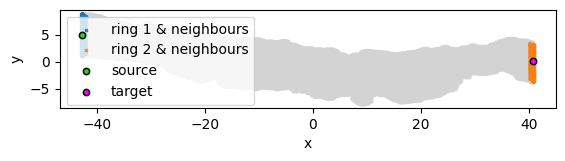

In [96]:
fig, ax = plt.subplots()

ax.scatter(*data.centroids[::50, [0,1]].T, **mesh_kwargs)
ax.scatter(*data.centroids[P1_neighbours][::20, [0,1]].T, s = 1, alpha = 0.15, color = "C0", edgecolors=None)
ax.scatter(*data.centroids[P2_neighbours][::20, [0,1]].T, s = 1, alpha = 0.15, color = "C1", edgecolors=None)

ax.scatter(*ring1[:, [0,1]].T, label = "ring 1 & neighbours", alpha = 0.8, color ="C0", zorder = -1, s = 2, marker = "s")
ax.scatter(*ring2[:, [0,1]].T, label = "ring 2 & neighbours", color = "C1", alpha = 0.8, zorder = -1, s =2, marker="s")

ax.scatter(*P1_in[[0,1]].T, **start_kwargs)
ax.scatter(*P2_in[[0,1]].T, **end_kwargs)
ax.legend()


ax.scatter(*P1[[0,1]].T, **start_kwargs, alpha = 0.15)
ax.scatter(*P2[[0,1]].T, **end_kwargs, alpha = 0.15)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_aspect("equal")
plt.savefig("../temp/figures/supplementary_ring_finding.png", dpi =300)
plt.show()

In [97]:
voxset_fp = mesh_fp[:-4] + "_voxset.vxl"
out_MST = return_MST_centrelines(mesh_fp, voxset_path=voxset_fp, 
                             delta = int(voxelsize*1000), 
                             P1=P1_in, 
                             P2=P2_in, 
                             verbose = False)



Read 'c:\Users\tangr\GitHub\pc-centrelines\data\10_faux_monnayeurs\faux_monnayeurs_voxset.vxl': 1,237,314 vertices and 31,416 grid points,
Added edges in 6.1 sec.
Computed maximum spanning tree for clearance in 0.8 sec.
Computed path in maximum spanning tree in 0.1 sec.


Added edges in 0.1 sec.
Computed shortest path in 0.0 sec.


Polyline has 210 vertices
Simplified polyline has 37 vertices


For demonstration purposes, we load the edges of voxels, the edges of the minimum spanning tree, the buffer edges. To colour the edges of the voxels by the clearance that was calculated so far, we also load the coordinates of the mid-points and colour them by clearance.

In [98]:
mst_centreline = out_MST["centerspline_direct"]
np.savetxt(f"../temp//{ID}_{CONDUIT_NAME}//mst//{CONDUIT_NAME}_{int(voxelsize*1000)}_centreline.txt", mst_centreline)

In [99]:
mst_centreline

array([[-4.26958008e+01,  4.89939990e+00, -2.39969995e+00],
       [-4.26144698e+01,  4.89705189e+00, -2.39970693e+00],
       [-4.25343358e+01,  4.89466762e+00, -2.39971380e+00],
       ...,
       [ 4.06695099e+01,  5.36476135e-02,  0.00000000e+00],
       [ 4.07169352e+01,  3.63382975e-02,  0.00000000e+00],
       [ 4.08000000e+01,  0.00000000e+00,  0.00000000e+00]],
      shape=(1213, 3))

In [100]:
edges = np.loadtxt(f"../temp//{ID}_{CONDUIT_NAME}//mst//{CONDUIT_NAME}_edges.xyz")
edges_mask = np.logical_and(edges[:, 2] == 0,edges[:, 5] == 0) 

In [101]:
vmin = np.min(edges[:, 6]/1000)
vmax = np.max(edges[:, 6]/1000)

norm = Normalize(vmin, vmax)
mappable = ScalarMappable(norm)

edges_midpoints = np.loadtxt(f"../temp//{ID}_{CONDUIT_NAME}//mst//{CONDUIT_NAME}_edges_midpoints.xyz")

In [102]:
# buffer edges grown around the minimum spanning tree. 
buffer_edges = np.loadtxt(f"../temp//{ID}_{CONDUIT_NAME}//mst//{CONDUIT_NAME}_unzigzag_edges.xyz")
buffer_edges_mask = np.logical_and(buffer_edges[:, 2] == 0, buffer_edges[:, 5] == 0) 

buffer_centreline = np.loadtxt(f"../temp//{ID}_{CONDUIT_NAME}//mst//{CONDUIT_NAME}_{int(voxelsize*1000)}_jagged_centreline.txt")

mst_edges = np.loadtxt(f"../temp//{ID}_{CONDUIT_NAME}//mst//{CONDUIT_NAME}_MST_edges.xyz")
mst_edges_mask = np.logical_and(edges[:, 2] == 0,edges[:, 5] == 0) 

In [103]:
smooth_centreline = np.loadtxt(f"../temp//{ID}_{CONDUIT_NAME}//mst//{CONDUIT_NAME}_{int(voxelsize*1000)}_centreline.txt")

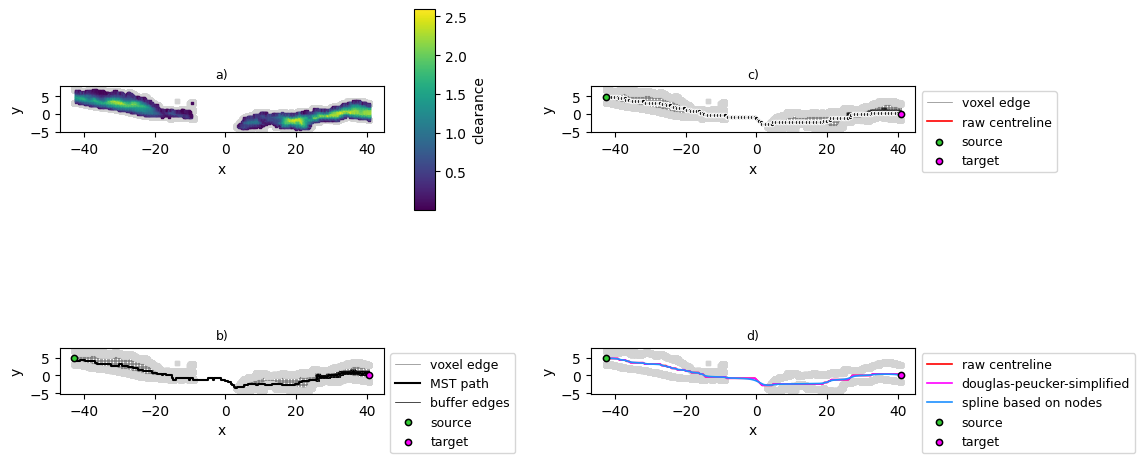

In [104]:
gs = GridSpec(9, 40)
fig = plt.figure(figsize = (13, 6))

##  the voxel clearance map figure. 
ax = fig.add_subplot(gs[0:4, :13])
for edge, edge_mask in zip(edges, edges_mask):
    if edge_mask:
        ax.plot(edge[[0,3]],edge[[1,4]], color = "grey", zorder = -25, lw = 0.5)


# plot the mesh only when centroids z coordinates are close to 
mesh_mask = np.abs(data.centroids[:, 2]) < 0.05
ax.scatter(*data.centroids[mesh_mask][:, [0, 1]].T, 
        **mesh_kwargs)

# plot voxel edges when their z coordinate is close to 0.
mask = np.abs(edges_midpoints[:, 2]) < 0.05
ax.scatter(*edges_midpoints[mask][:, [0, 1]].T, c=edges_midpoints[mask, 3], zorder = -10, marker="s", s= 2)

# set up the colorbar.
cax = fig.add_subplot(gs[0:4, 14:15])
cb = plt.colorbar(mappable, cax =cax, fraction=0.01)
cb.set_label("clearance")
ax.set_aspect("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("a)", fontdict= dict(fontsize=9))

## unzizag path plot. 
ax = fig.add_subplot(gs[5:, :13])
for edge, edge_mask in zip(edges, edges_mask):
    if edge_mask:
        ax.plot(edge[[0,3]],edge[[1,4]], color = "grey", zorder = -25, lw = 0.5)
ax.plot(edges[0,[0,3]],edges[0,[1,4]], color = "grey", zorder = -25, lw = 0.5, label ="voxel edge")

# plot the mesh 
mesh_mask = np.abs(data.centroids[:, 2]) < 0.05
ax.scatter(*data.centroids[mesh_mask][:, [0, 1]].T, 
        **mesh_kwargs)


ax.set_title("b)", fontdict= dict(fontsize=9))

# plot the jagged centreline
ax.plot(*buffer_centreline[:, [0, 1]].T, zorder = 100, color = "k", label = "MST path")
ax.plot(*buffer_centreline[:, [0, 1]].T, zorder = 95, color = "white", lw = 1.5)

for buffer_edge, buffer_edge_mask in zip(buffer_edges, buffer_edges_mask):
    if buffer_edge_mask:
        ax.plot(buffer_edge[[0,3]],buffer_edge[[1,4]], color = "k", zorder = -10, lw = 0.5)

ax.plot(buffer_edges[0, [0,3]],buffer_edges[0, [1,4]], color = "k", zorder = -10, lw = 0.5, label ="buffer edges")


# plot the source and target
ax.scatter(*P1_in[[0, 1]],**start_kwargs)
ax.scatter(*P2_in[[0, 1]], **end_kwargs)

# define the colorbar for the mesh midpoints. 
ax.legend(loc = "upper left", bbox_to_anchor= (1,1.02), fontsize = 9)
ax.set_aspect("equal")

ax.set_xlabel("x")
ax.set_ylabel("y")

ax = fig.add_subplot(gs[0:4, 21:-6])
for edge, edge_mask in zip(edges, edges_mask):
    if edge_mask:
        ax.plot(edge[[0,3]],edge[[1,4]], color = "grey", zorder = -20, lw = 0.5)
ax.plot(edges[0,[0,3]],edges[0,[1,4]], color = "grey", zorder = -25, lw = 0.5, label ="voxel edge")


# plot the centreline
ax.plot(*np.array(out_MST["raw"])[:, [0, 1]].T,**ct_kwargs, label = "raw centreline")
# plot the centreline nodes
ax.scatter(*np.array(out_MST["raw"])[:, [0, 1]].T, 
        **node_kwargs)
for buffer_edge, buffer_edge_mask in zip(buffer_edges, buffer_edges_mask):
    if buffer_edge_mask:
        ax.plot(buffer_edge[[0,3]],buffer_edge[[1,4]], color = "k", zorder = -10, lw = 0.25)


ax.set_title("c)", fontdict= dict(fontsize=9))

# plot the source and target
ax.scatter(*P1_in[[0, 1]],**start_kwargs)
ax.scatter(*P2_in[[0, 1]], **end_kwargs)


# plot the mesh 
mesh_mask = np.abs(data.centroids[:, 2]) < 0.05
ax.scatter(*data.centroids[mesh_mask][:, [0, 1]].T, 
        **mesh_kwargs)

ax.legend(loc = "upper left", bbox_to_anchor= (1,1.02), fontsize = 9)
ax.set_aspect("equal")

ax.set_xlabel("x")
ax.set_ylabel("y")


ax = fig.add_subplot(gs[5:, 21:-6])


# plot the centreline
ax.plot(*np.array(out_MST["raw"])[:, [0, 1]].T,**ct_kwargs, label = "raw centreline")
# plot the centreline nodes
ax.plot(*np.array(out_MST["simplified"])[:, [0, 1]].T,**ct1_kwargs, label = "douglas-peucker-simplified")
ax.plot(*np.array(out_MST["centerspline_direct"])[:, [0, 1]].T,**ct2_kwargs, label = "spline based on nodes")

ax.set_title("d)", fontdict= dict(fontsize=9))

# plot the source and target
ax.scatter(*P1_in[[0, 1]],**start_kwargs)
ax.scatter(*P2_in[[0, 1]], **end_kwargs)


# plot the mesh 
mesh_mask = np.abs(data.centroids[:, 2]) < 0.05
ax.scatter(*data.centroids[mesh_mask][:, [0, 1]].T, 
        **mesh_kwargs)

ax.legend(loc = "upper left", bbox_to_anchor= (1,1.02), fontsize = 9)
ax.set_aspect("equal")

ax.set_xlabel("x")
ax.set_ylabel("y")


plt.savefig(f"../temp/{ID}_{CONDUIT_NAME}/mst/{CONDUIT_NAME}_edge_clearance_map.png", dpi = 300)
plt.savefig(f"../temp/{ID}_{CONDUIT_NAME}/mst/{CONDUIT_NAME}_edge_clearance_map.pdf")

plt.show()